# Notebook 03 — Vision-Only Baseline
**Goal:** Train a MobileNet-V3 Small image classifier to see how well vision alone performs,
especially on the Fresh vs Formalin-Mixed distinction.

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
import torchvision.models as models

warnings.filterwarnings('ignore')

TARGET_NAMES = ['Fresh', 'Formalin-Mixed', 'Rotten']
RESULTS_DIR = '../results'
MODELS_DIR = '../models'
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)

# Hyperparameters
IMG_SIZE = 224
BATCH_SIZE = 32
FREEZE_EPOCHS = 3
FINETUNE_EPOCHS = 12
LR_HEAD = 3e-4
LR_FINETUNE = 3e-5

## 1. Dataset

In [2]:
class LitchiImageDataset(Dataset):
    def __init__(self, csv_path, transform=None):
        self.df = pd.read_csv(csv_path)
        self.transform = transform
        self.labels = self.df['label'].values
        self.paths = self.df['image_path'].values

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img = Image.open(self.paths[idx]).convert('RGB')
        if self.transform:
            img = self.transform(img)
        label = torch.tensor(self.labels[idx], dtype=torch.long)
        return img, label

# Transforms
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])
val_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

train_ds = LitchiImageDataset('../data/processed/train.csv', train_transform)
val_ds = LitchiImageDataset('../data/processed/val.csv', val_transform)
test_ds = LitchiImageDataset('../data/processed/test.csv', val_transform)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print(f"Train: {len(train_ds)}, Val: {len(val_ds)}, Test: {len(test_ds)}")

Train: 2099, Val: 451, Test: 450


## 2. Model: MobileNet-V3 Small

In [3]:
base = models.mobilenet_v3_small(weights='DEFAULT')
in_features = base.classifier[0].in_features
base.classifier = nn.Sequential(
    nn.Linear(in_features, 128),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(128, 3)
)
model = base

total_params = sum(p.numel() for p in model.parameters())
print(f"Total parameters: {total_params:,}")

Total parameters: 1,001,251


## 3. Training

In [4]:
def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    total_loss, correct, total = 0, 0, 0
    for imgs, labels in loader:
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(labels)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += len(labels)
    return total_loss / total, correct / total

def evaluate(model, loader, criterion):
    model.eval()
    total_loss, correct, total = 0, 0, 0
    with torch.no_grad():
        for imgs, labels in loader:
            outputs = model(imgs)
            loss = criterion(outputs, labels)
            total_loss += loss.item() * len(labels)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += len(labels)
    return total_loss / total, correct / total

In [5]:
criterion = nn.CrossEntropyLoss()
history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
best_val_acc = 0
best_weights = None

# Phase 1: Freeze backbone, train classifier head only
for param in model.features.parameters():
    param.requires_grad = False
optimizer = torch.optim.Adam(model.classifier.parameters(), lr=LR_HEAD)

print("Phase 1: Training classifier head (backbone frozen)")
for epoch in range(1, FREEZE_EPOCHS + 1):
    tl, ta = train_one_epoch(model, train_loader, criterion, optimizer)
    vl, va = evaluate(model, val_loader, criterion)
    history["train_loss"].append(tl)
    history["val_loss"].append(vl)
    history["train_acc"].append(ta)
    history["val_acc"].append(va)
    if va > best_val_acc:
        best_val_acc = va
        best_weights = {k: v.clone() for k, v in model.state_dict().items()}
    print(f"  Epoch {epoch}/{FREEZE_EPOCHS}  |  Train Loss: {tl:.4f}  Acc: {ta*100:.1f}%  |  Val Loss: {vl:.4f}  Acc: {va*100:.1f}%")

# Phase 2: Unfreeze all layers and fine-tune
for param in model.parameters():
    param.requires_grad = True
optimizer = torch.optim.AdamW(model.parameters(), lr=LR_FINETUNE, weight_decay=1e-3)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=FINETUNE_EPOCHS)

print("\nPhase 2: Fine-tuning all layers")
for epoch in range(1, FINETUNE_EPOCHS + 1):
    tl, ta = train_one_epoch(model, train_loader, criterion, optimizer)
    vl, va = evaluate(model, val_loader, criterion)
    scheduler.step()
    history["train_loss"].append(tl)
    history["val_loss"].append(vl)
    history["train_acc"].append(ta)
    history["val_acc"].append(va)
    if va > best_val_acc:
        best_val_acc = va
        best_weights = {k: v.clone() for k, v in model.state_dict().items()}
    print(f"  Epoch {epoch}/{FINETUNE_EPOCHS}  |  Train Loss: {tl:.4f}  Acc: {ta*100:.1f}%  |  Val Loss: {vl:.4f}  Acc: {va*100:.1f}%")

model.load_state_dict(best_weights)
print(f"\nBest Val Accuracy: {best_val_acc*100:.2f}%")

Phase 1: Training classifier head (backbone frozen)
  Epoch 1/3  |  Train Loss: 0.6736  Acc: 83.7%  |  Val Loss: 0.5931  Acc: 82.5%
  Epoch 2/3  |  Train Loss: 0.2767  Acc: 94.4%  |  Val Loss: 0.2540  Acc: 96.0%
  Epoch 3/3  |  Train Loss: 0.1723  Acc: 96.6%  |  Val Loss: 0.1509  Acc: 96.5%

Phase 2: Fine-tuning all layers
  Epoch 1/12  |  Train Loss: 0.0885  Acc: 97.9%  |  Val Loss: 0.0465  Acc: 99.3%
  Epoch 2/12  |  Train Loss: 0.0423  Acc: 99.0%  |  Val Loss: 0.0259  Acc: 99.8%
  Epoch 3/12  |  Train Loss: 0.0335  Acc: 99.1%  |  Val Loss: 0.0144  Acc: 100.0%
  Epoch 4/12  |  Train Loss: 0.0223  Acc: 99.4%  |  Val Loss: 0.0082  Acc: 100.0%
  Epoch 5/12  |  Train Loss: 0.0207  Acc: 99.6%  |  Val Loss: 0.0068  Acc: 100.0%
  Epoch 6/12  |  Train Loss: 0.0186  Acc: 99.5%  |  Val Loss: 0.0057  Acc: 100.0%
  Epoch 7/12  |  Train Loss: 0.0165  Acc: 99.6%  |  Val Loss: 0.0042  Acc: 100.0%
  Epoch 8/12  |  Train Loss: 0.0179  Acc: 99.6%  |  Val Loss: 0.0035  Acc: 100.0%
  Epoch 9/12  |  Trai

## 4. Training Curves

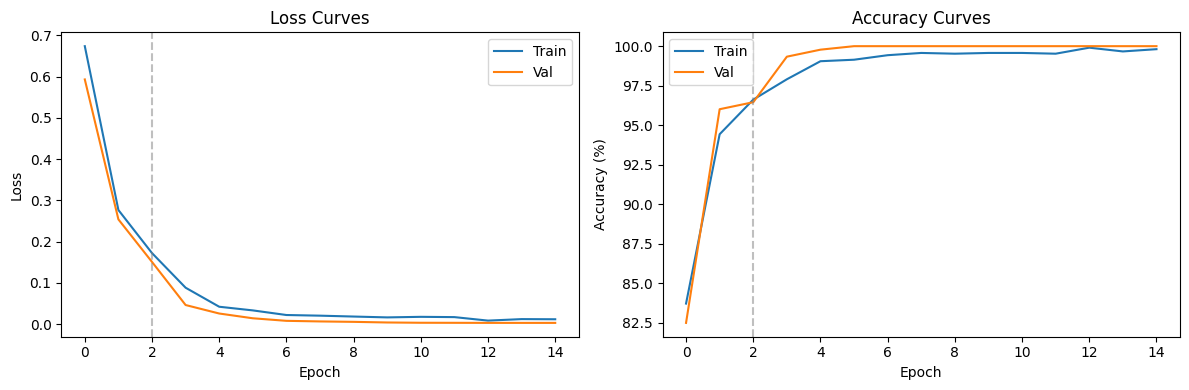

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(history["train_loss"], label="Train")
ax1.plot(history["val_loss"], label="Val")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.set_title("Loss Curves")
ax1.legend()
ax1.axvline(x=FREEZE_EPOCHS-1, color="gray", linestyle="--", alpha=0.5, label="Unfreeze")

ax2.plot([a*100 for a in history["train_acc"]], label="Train")
ax2.plot([a*100 for a in history["val_acc"]], label="Val")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Accuracy (%)")
ax2.set_title("Accuracy Curves")
ax2.legend()
ax2.axvline(x=FREEZE_EPOCHS-1, color="gray", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "vision_training_curves.png"), bbox_inches="tight")
plt.show()

## 5. Test Set Evaluation

Vision Baseline  ->  Accuracy: 98.44%  |  Macro F1: 0.9844
                precision    recall  f1-score   support

         Fresh       0.98      0.97      0.98       150
Formalin-Mixed       1.00      1.00      1.00       150
        Rotten       0.97      0.98      0.98       150

      accuracy                           0.98       450
     macro avg       0.98      0.98      0.98       450
  weighted avg       0.98      0.98      0.98       450



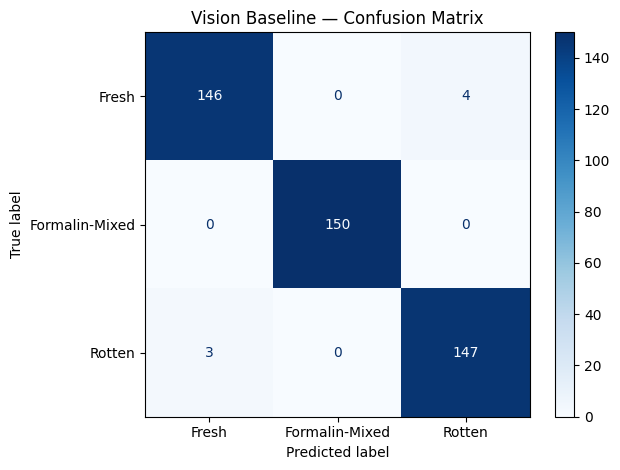

In [7]:
model.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for imgs, labels in test_loader:
        all_preds.extend(model(imgs).argmax(1).numpy())
        all_labels.extend(labels.numpy())

vis_acc = accuracy_score(all_labels, all_preds)
vis_f1 = f1_score(all_labels, all_preds, average='macro')
print(f"Vision Baseline  ->  Accuracy: {vis_acc*100:.2f}%  |  Macro F1: {vis_f1:.4f}")
print(classification_report(all_labels, all_preds, target_names=TARGET_NAMES))

cm = confusion_matrix(all_labels, all_preds)
disp = ConfusionMatrixDisplay(cm, display_labels=TARGET_NAMES)
disp.plot(cmap="Blues")
plt.title("Vision Baseline — Confusion Matrix")
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "vision_confusion_matrix.png"), bbox_inches="tight")
plt.show()

## 6. Save Model

In [8]:
torch.save(model.state_dict(), os.path.join(MODELS_DIR, "vision_baseline.pth"))
print(f"Saved to {MODELS_DIR}/vision_baseline.pth")

Saved to ../models/vision_baseline.pth
